# Preprocessing data kecelakaan lalu lintas Chicago

**Nama:** Ahmad Maulana Ibrahim  
**NIM:** 24/539655/TK/59853  
**Mata kuliah:** Rekayasa Data 2026/2027

Notebook ini mengolah salinan lokal tahun 2018–2025. Alurnya: profil data mentah → cleaning → integrasi → pemeriksaan redundansi → reduksi atribut dan agregasi → perbandingan hasil. Seluruh angka dihitung dari file lokal, bukan jumlah terkini di portal.

## 1. Dataset dan alasan pemilihan

Data kecelakaan Chicago dipilih karena tiga tabelnya saling terhubung, memiliki nilai kosong dan kualitas geospasial yang perlu diaudit, serta memungkinkan analisis kejadian, kendaraan, dan orang pada grain yang berbeda.

| Data resmi | Grain | Tautan sumber |
|---|---|---|
| Traffic Crashes - Crashes | Satu kecelakaan | [City of Chicago: Crashes](https://data.cityofchicago.org/Transportation/Traffic-Crashes-Crashes/85ca-t3if/about_data) |
| Traffic Crashes - Vehicles | Satu unit/kendaraan | [City of Chicago: Vehicles](https://data.cityofchicago.org/Transportation/Traffic-Crashes-Vehicles/68nd-jvt3/about_data) |
| Traffic Crashes - People | Satu orang | [City of Chicago: People](https://data.cityofchicago.org/Transportation/Traffic-Crashes-People/u6pd-qa9d/about_data) |
| Boundaries - Community Areas | Satu poligon area | [City of Chicago: Community Areas](https://data.cityofchicago.org/d/igwz-8jzy) |

Kunci penghubung tiga tabel utama adalah `crash_record_id`. Pencocokan orang ke unit memerlukan `vehicle_id` dan kecelakaan yang sama. Berkas CSV mentah serta GeoJSON referensi tidak ditimpa.

## 2. Persiapan dan profil kondisi awal

CSV besar dibaca per chunk untuk menjaga penggunaan memori. Seluruh atribut sumber diprofilkan; duplikat baris dan ID dihitung menggunakan hash 64-bit. Nilai putih kosong dinormalisasi pada tahap cleaning berikutnya.

In [1]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 80)
plt.style.use("seaborn-v0_8-whitegrid")

DATA_DIR = Path("./chicago_traffic")
FILES = {
    "Crashes": DATA_DIR / "traffic_crashes_crashes_2018_2025.csv",
    "Vehicle": DATA_DIR / "traffic_crashes_vehicles_2018_2025.csv",
    "People": DATA_DIR / "traffic_crashes_people_2018_2025.csv",
}

missing_files = [str(path) for path in FILES.values() if not path.exists()]
assert not missing_files, f"File tidak ditemukan: {missing_files}"

pd.DataFrame({
    "dataset": FILES.keys(),
    "file": [p.name for p in FILES.values()],
    "ukuran_mb": [round(p.stat().st_size / 1024**2, 2) for p in FILES.values()],
})

,dataset,file,ukuran_mb
0,Crashes,traffic_crashes_crashes_2018_2025.csv,527.77
1,Vehicle,traffic_crashes_vehicles_2018_2025.csv,612.07
2,People,traffic_crashes_people_2018_2025.csv,629.61


In [2]:
CRASH_COLS = [
    "crash_record_id", "crash_date", "posted_speed_limit",
    "traffic_control_device", "device_condition", "weather_condition",
    "lighting_condition", "first_crash_type", "trafficway_type",
    "alignment", "roadway_surface_cond", "road_defect",
    "crash_type", "prim_contributory_cause", "sec_contributory_cause",
    "damage", "intersection_related_i", "hit_and_run_i",
    "work_zone_i", "num_units", "most_severe_injury",
    "injuries_total", "injuries_fatal", "injuries_incapacitating",
    "crash_hour", "crash_day_of_week", "latitude", "longitude",
]

VEHICLE_COLS = [
    "crash_unit_id", "crash_record_id", "unit_no", "unit_type",
    "num_passengers", "vehicle_id", "vehicle_year",
    "vehicle_defect", "vehicle_type", "vehicle_use",
    "travel_direction", "maneuver", "occupant_cnt",
    "exceed_speed_limit_i", "first_contact_point",
]

PEOPLE_COLS = [
    "person_id", "person_type", "crash_record_id", "vehicle_id",
    "seat_no", "sex", "age", "safety_equipment",
    "airbag_deployed", "ejection", "injury_classification",
    "driver_action", "driver_vision", "physical_condition",
    "pedpedal_action", "pedpedal_visibility", "pedpedal_location",
    "bac_result", "bac_result_value", "cell_phone_use",
]


CHUNK_SIZE = 20_000
SELECTED_COLS = {
    "Crashes": CRASH_COLS,
    "Vehicle": VEHICLE_COLS,
    "People": PEOPLE_COLS,
}


def load_and_profile(path, keep_cols, id_col, chunksize=CHUNK_SIZE):
    columns = pd.read_csv(path, nrows=0).columns
    absent = set(keep_cols + [id_col]) - set(columns)
    if absent:
        raise KeyError(f"Kolom tidak ditemukan di {path.name}: {sorted(absent)}")

    row_count = 0
    memory_bytes = 0
    missing_counts = pd.Series(0, index=columns, dtype="int64")
    row_hash_parts = []
    id_hash_parts = []

    for chunk in pd.read_csv(path, dtype="string", chunksize=chunksize):
        row_count += len(chunk)
        memory_bytes += int(chunk.memory_usage(index=False, deep=True).sum())
        missing_counts += chunk.isna().sum()
        row_hash_parts.append(pd.util.hash_pandas_object(chunk, index=False).to_numpy())
        id_hash_parts.append(pd.util.hash_pandas_object(chunk[id_col], index=False).to_numpy())

    row_hashes = np.concatenate(row_hash_parts) if row_hash_parts else np.array([], dtype="uint64")
    id_hashes = np.concatenate(id_hash_parts) if id_hash_parts else np.array([], dtype="uint64")
    profile = {
        "baris": row_count,
        "kolom": len(columns),
        "sel_kosong": int(missing_counts.sum()),
        "duplikat_penuh": int(row_count - np.unique(row_hashes).size),
        "duplikat_id": int(row_count - np.unique(id_hashes).size),
        "memori_mb": round(memory_bytes / 1024**2, 2),
    }
    missing = missing_counts.rename("jumlah_kosong").to_frame()
    missing["persen"] = (100 * missing["jumlah_kosong"] / row_count).round(2) if row_count else 0.0
    missing = missing.query("jumlah_kosong > 0").sort_values("jumlah_kosong", ascending=False)
    return profile, missing


def iter_selected(dataset, chunksize=CHUNK_SIZE):
    """Baca kolom terpilih per chunk tanpa menyimpan seluruh tabel di RAM."""
    return pd.read_csv(
        FILES[dataset], usecols=SELECTED_COLS[dataset],
        dtype="string", chunksize=chunksize,
    )


crash_profile, crash_missing = load_and_profile(
    FILES["Crashes"], CRASH_COLS, "crash_record_id"
)
vehicle_profile, vehicle_missing = load_and_profile(
    FILES["Vehicle"], VEHICLE_COLS, "crash_unit_id"
)
people_profile, people_missing = load_and_profile(
    FILES["People"], PEOPLE_COLS, "person_id"
)

initial_profile = pd.DataFrame(
    [crash_profile, vehicle_profile, people_profile],
    index=["Crashes", "Vehicle", "People"],
)
initial_profile

,baris,kolom,sel_kosong,duplikat_penuh,duplikat_id,memori_mb
Crashes,877921,49,9001923,0,0,2820.40
Vehicle,1792372,71,93017957,0,0,7964.05
People,1927657,29,22063385,0,0,3697.74


### Seleksi awal berdasarkan kelengkapan

Atribut dengan **lebih dari 30%** nilai kosong dikeluarkan dari tahap cleaning. Ambang ini hanya untuk atribut, bukan baris, sehingga kunci dan kejadian tidak hilang. Kolom yang masih kosong setelah cleaning dipertahankan bila tidak dapat direkonstruksi dengan bukti yang cukup.

In [3]:
MISSING_THRESHOLD = 0.30
MISSING_TABLES = {
    "Crashes": crash_missing,
    "Vehicle": vehicle_missing,
    "People": people_missing,
}
ORIGINAL_SELECTED_COLS = {
    "Crashes": CRASH_COLS,
    "Vehicle": VEHICLE_COLS,
    "People": PEOPLE_COLS,
}

DROPPED_COLS = {}
REMAINING_COLS = {}
SELECTED_COLS = {}
summary_rows = []
dropped_rows = []

for dataset, missing in MISSING_TABLES.items():
    row_count = int(initial_profile.loc[dataset, "baris"])
    source_cols = pd.read_csv(FILES[dataset], nrows=0).columns.tolist()
    above_threshold = missing["jumlah_kosong"] > MISSING_THRESHOLD * row_count
    DROPPED_COLS[dataset] = missing.index[above_threshold].tolist()
    dropped_set = set(DROPPED_COLS[dataset])
    REMAINING_COLS[dataset] = [col for col in source_cols if col not in dropped_set]
    SELECTED_COLS[dataset] = [
        col for col in ORIGINAL_SELECTED_COLS[dataset] if col not in dropped_set
    ]
    summary_rows.append({
        "dataset": dataset,
        "atribut_awal": len(source_cols),
        "atribut_dihapus": len(DROPPED_COLS[dataset]),
        "atribut_tersisa": len(REMAINING_COLS[dataset]),
        "subset_analisis_tersisa": len(SELECTED_COLS[dataset]),
    })
    for col in DROPPED_COLS[dataset]:
        dropped_rows.append({
            "dataset": dataset,
            "atribut": col,
            "jumlah_kosong": int(missing.loc[col, "jumlah_kosong"]),
            "persen_kosong": round(100 * missing.loc[col, "jumlah_kosong"] / row_count, 2),
        })

def iter_remaining(dataset, chunksize=CHUNK_SIZE):
    """Baca atribut sumber yang lolos ambang kosong per chunk."""
    return pd.read_csv(
        FILES[dataset], usecols=REMAINING_COLS[dataset],
        dtype="string", chunksize=chunksize,
    )

attribute_summary = pd.DataFrame(summary_rows).set_index("dataset")
attribute_summary.loc["Total"] = attribute_summary.sum()
dropped_attributes = pd.DataFrame(dropped_rows)
display(attribute_summary, dropped_attributes)

,atribut_awal,atribut_dihapus,atribut_tersisa,subset_analisis_tersisa
dataset,,,,
Crashes,49,11,38,25
Vehicle,71,54,17,13
People,29,12,17,14
Total,149,77,72,52


,dataset,atribut,jumlah_kosong,persen_kosong
0,Crashes,workers_present_i,876718,99.86
1,Crashes,dooring_i,875109,99.68
2,Crashes,work_zone_type,874594,99.62
3,Crashes,work_zone_i,873548,99.50
4,Crashes,photos_taken_i,865475,98.58
...,...,...,...,...
72,People,hospital,1621249,84.10
73,People,seat_no,1536625,79.71
74,People,drivers_license_class,1008930,52.34
75,People,drivers_license_state,800216,41.51


## 3. Data cleaning

Kode berikut menormalisasi spasi, tipe tanggal/angka, kategori, dan nilai kosong; mempertahankan nilai sumber dalam `age_raw` dan `vehicle_year_raw`; serta menerapkan batas domain umur 0–120 dan tahun kendaraan 1900 sampai satu tahun setelah tahun kecelakaan. Angka cedera hanya direkonstruksi dari komponen yang lengkap dan konsisten. Setiap keputusan dicatat dalam audit. Pemrosesan Parquet dan indeks SQLite berlangsung per batch agar data besar tidak harus dimuat sekaligus.
Implementasi cleaning berada di `traffic_crash_pipeline.py` agar aturan transformasi dapat dibaca dan digunakan ulang di luar notebook.

In [4]:
from traffic_crash_pipeline import MissingValuePipeline, ParquetStream, parquet_chunks


### Menjalankan cleaning dan memeriksa kunci

In [5]:
pipeline = MissingValuePipeline(FILES, REMAINING_COLS, initial_profile, DATA_DIR, CHUNK_SIZE)
missing_value_audit, clean_validation = pipeline.run()
display(clean_validation[["dataset", "baris_sumber", "baris_bersih", "duplikat_id_bersih", "kunci_kosong", "kolom_bersih", "tipe_numerik_valid"]])
audit_focus = missing_value_audit.loc[
    missing_value_audit["metrik"].astype("string").str.contains("join_people|join_vehicles|people_injury_conflict|num_units_conflict|valid_coordinates|geo_missing", na=False),
    ["dataset", "metrik", "jumlah_metrik"],
]
display(audit_focus)

,dataset,baris_sumber,baris_bersih,duplikat_id_bersih,kunci_kosong,kolom_bersih,tipe_numerik_valid
0,Crashes,877921,877921,0,0,44,True
1,Vehicle,1792372,1792372,0,0,21,True
2,People,1927657,1927657,0,0,24,True


,dataset,metrik,jumlah_metrik
82,Crashes,geo_missing,7068
105,Crashes,join_people_failure,1987
106,Crashes,join_people_success,875934
107,Crashes,join_vehicles_failure,0
108,Crashes,join_vehicles_success,877921
109,Crashes,num_units_conflict,1901
110,Crashes,people_injury_conflict,1895
111,Crashes,valid_coordinates,870853


### Nilai yang sengaja tetap kosong

Koordinat, umur, atau hitungan cedera tanpa dasar yang cukup tidak dipaksakan menjadi angka. Kategori `TIDAK_TERCATAT` dan `TIDAK_BERLAKU` dipakai hanya ketika maknanya dapat dibedakan.

In [6]:
remaining_nulls = (
    missing_value_audit.loc[
        missing_value_audit["kolom"].notna() & pd.to_numeric(missing_value_audit["tetap_null"], errors="coerce").gt(0),
        ["dataset", "kolom", "kosong_sebelum", "kosong_sesudah"],
    ]
    .drop_duplicates(["dataset", "kolom"])
    .sort_values(["dataset", "kosong_sesudah"], ascending=[True, False])
)
display(remaining_nulls)

,dataset,kolom,kosong_sebelum,kosong_sesudah
35,Crashes,latitude,7068.0,7068.0
36,Crashes,longitude,7068.0,7068.0
37,Crashes,location,7068.0,7068.0
34,Crashes,idot_control_no,2651.0,2651.0
25,Crashes,injuries_total,1987.0,1987.0
26,Crashes,injuries_fatal,1987.0,1987.0
27,Crashes,injuries_incapacitating,1987.0,1987.0
28,Crashes,injuries_non_incapacitating,1987.0,1987.0
29,Crashes,injuries_reported_not_evident,1987.0,1987.0
30,Crashes,injuries_no_indication,1987.0,1987.0


### Outlier domain dan perbandingan nilai kosong

Umur di luar 0–120 dan tahun kendaraan yang tidak masuk akal dijadikan `NULL` pada kolom bersih; baris tetap dipertahankan dan nilai sumber masih dapat diperiksa. Ekstrem statistik pada jumlah orang/unit tidak dihapus otomatis karena dapat mewakili kecelakaan nyata. Grafik membandingkan atribut yang sama pada sumber dan hasil cleaning.

,dataset,aturan,nilai_dijadikan_null
113,People,invalid_domain:age,8
125,Vehicle,invalid_domain:vehicle_year,1073


,dataset,atribut,sebelum_pct,sesudah_pct
0,Crashes,report_type,3.64,0.00
1,Crashes,injuries_total,0.23,0.23
2,Crashes,latitude,0.81,0.81
3,Vehicle,make,2.48,0.00
4,Vehicle,vehicle_year,17.79,17.85
5,People,city,27.34,0.00
6,People,age,28.86,28.86
7,People,injury_classification,0.03,0.00


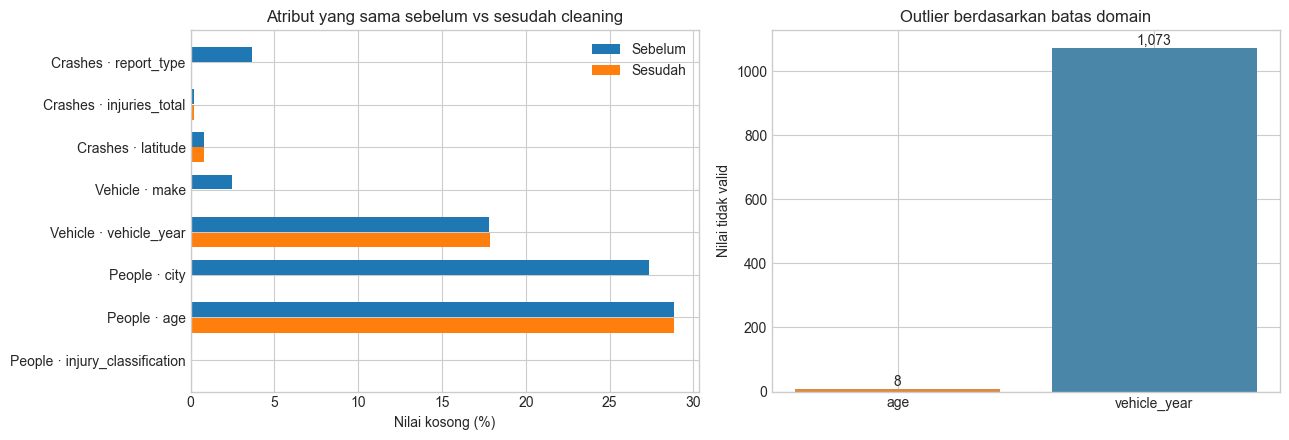

In [7]:
# Batas domain yang dipakai saat cleaning; nilai aslinya masih ada di *_raw.
domain_outliers = missing_value_audit.loc[
    missing_value_audit["metrik"].isin(["invalid_domain:age", "invalid_domain:vehicle_year"]),
    ["dataset", "metrik", "jumlah_metrik"],
].copy()
domain_outliers["jumlah_metrik"] = domain_outliers["jumlah_metrik"].astype(int)
display(domain_outliers.rename(columns={"metrik": "aturan", "jumlah_metrik": "nilai_dijadikan_null"}))

# Bandingkan atribut sumber yang sama; atribut turunan tidak masuk penyebut.
fields = {"Crashes": ["report_type", "injuries_total", "latitude"],
          "Vehicle": ["make", "vehicle_year"],
          "People": ["city", "age", "injury_classification"]}
rows = []
for dataset, columns in fields.items():
    n = int(initial_profile.loc[dataset, "baris"])
    for column in columns:
        found = missing_value_audit.loc[(missing_value_audit["dataset"] == dataset) &
                                        (missing_value_audit["kolom"] == column)].iloc[0]
        rows.append({"dataset": dataset, "atribut": column,
                     "sebelum_pct": 100 * found["kosong_sebelum"] / n,
                     "sesudah_pct": 100 * found["kosong_sesudah"] / n})
missing_comparison = pd.DataFrame(rows)
display(missing_comparison.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
labels = missing_comparison["dataset"] + " · " + missing_comparison["atribut"]
x = np.arange(len(labels))
axes[0].barh(x - .18, missing_comparison["sebelum_pct"], height=.35, label="Sebelum")
axes[0].barh(x + .18, missing_comparison["sesudah_pct"], height=.35, label="Sesudah")
axes[0].set_yticks(x, labels)
axes[0].invert_yaxis()
axes[0].set_xlabel("Nilai kosong (%)")
axes[0].legend()
axes[0].set_title("Atribut yang sama sebelum vs sesudah cleaning")
axes[1].bar(domain_outliers["metrik"].str.replace("invalid_domain:", ""),
            domain_outliers["jumlah_metrik"], color=["#dc8a43", "#4986a8"])
axes[1].set_ylabel("Nilai tidak valid")
axes[1].set_title("Outlier berdasarkan batas domain")
for bar in axes[1].patches:
    axes[1].annotate(f"{bar.get_height():,.0f}", (bar.get_x() + bar.get_width()/2, bar.get_height()),
                     ha="center", va="bottom")
plt.tight_layout()
plt.show()

## 4. Estimasi tambahan dan pemetaan area

Salinan analisis (`*_estimated`) disimpan terpisah dari nilai sumber. Total cedera kosong hanya diestimasi nol jika jenis kecelakaan menyatakan tidak ada cedera. Pencarian alamat US Census memakai cache dan hanya menerima kecocokan tepat; koordinat perkiraan adalah posisi rentang alamat, bukan titik kejadian yang terverifikasi. Poligon dari portal Chicago menghubungkan titik ke 77 community area. Status asal koordinat disimpan untuk audit.

In [8]:
"""Add evidence-tracked estimates without overwriting source fields."""
import csv
import io
import re
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import pyarrow.parquet as pq


PROCESSED_DIR = DATA_DIR / "processed"
CRASH_INPUT = PROCESSED_DIR / "clean_crashes.parquet"
CRASH_ENRICHED = PROCESSED_DIR / "clean_crashes_enriched.parquet"
GEOCODE_CACHE = PROCESSED_DIR / "census_geocode_cache.csv"
EXTENSION_AUDIT = PROCESSED_DIR / "estimation_extension_audit.csv"
GEOCODE_BATCH_SIZE = 2500
GEOCODE_URL = "https://geocoding.geo.census.gov/geocoder/locations/addressbatch"
GEOCODE_BENCHMARK = "Public_AR_Current"


def _standard_address(street_no, direction, street_name):
    if any(pd.isna(value) for value in (street_no, direction, street_name)):
        return None
    return f"{int(street_no)} {str(direction).strip()} {str(street_name).strip()}".upper()


def _canonical_street(address):
    """Compare the house number, direction, and street; ignore city and ZIP."""
    address = str(address).split(",", 1)[0].upper().replace(".", " ")
    for word, abbr in (
        ("BOULEVARD", "BLVD"), ("AVENUE", "AVE"), ("STREET", "ST"),
        ("DRIVE", "DR"), ("ROAD", "RD"), ("PLACE", "PL"),
        ("COURT", "CT"), ("PARKWAY", "PKWY"), ("TERRACE", "TER"),
    ):
        address = re.sub(rf"\b{word}\b", abbr, address)
    return " ".join(address.split())


def _valid_chicago_pair(latitude, longitude):
    # Broad city envelope; this is a sanity check, not a boundary polygon.
    return 41.5 <= latitude <= 42.1 and -88.1 <= longitude <= -87.4


# Collect rows needing address-based coordinate estimates.
geo_missing_rows = []
for crash_chunk in parquet_chunks(CRASH_INPUT, CHUNK_SIZE):
    geo_missing = crash_chunk["latitude"].isna() & crash_chunk["longitude"].isna()
    cols = ["crash_record_id", "street_no", "street_direction", "street_name"]
    for crash_id, street_no, direction, street_name in crash_chunk.loc[geo_missing, cols].itertuples(index=False, name=None):
        address = _standard_address(street_no, direction, street_name)
        geo_missing_rows.append((str(crash_id), address))


# Reuse successful and unsuccessful responses so reruns have stable results.
geocode_cache = {}
if GEOCODE_CACHE.exists():
    with GEOCODE_CACHE.open("r", encoding="utf-8", newline="") as stream:
        for row in csv.DictReader(stream):
            geocode_cache[row["crash_record_id"]] = row

pending = [(crash_id, address) for crash_id, address in geo_missing_rows
           if address is not None and crash_id not in geocode_cache]
geocode_errors = []
for start in range(0, len(pending), GEOCODE_BATCH_SIZE):
    batch = pending[start:start + GEOCODE_BATCH_SIZE]
    request_csv = io.StringIO()
    writer = csv.writer(request_csv)
    index_to_record = {}
    for index, (crash_id, address) in enumerate(batch):
        index_to_record[str(index)] = (crash_id, address)
        writer.writerow([index, address, "Chicago", "IL", ""])
    try:
        response = requests.post(
            GEOCODE_URL,
            data={"benchmark": GEOCODE_BENCHMARK},
            files={"addressFile": ("addresses.csv", request_csv.getvalue().encode("utf-8"), "text/csv")},
            timeout=120,
        )
        response.raise_for_status()
        returned = {}
        for row in csv.reader(io.StringIO(response.text)):
            if not row or row[0] not in index_to_record:
                continue
            crash_id, address = index_to_record[row[0]]
            status = row[2] if len(row) > 2 else "MALFORMED"
            match_type = row[3] if len(row) > 3 else ""
            matched_address = row[4] if len(row) > 4 else ""
            coordinate_text = row[5] if len(row) > 5 else ""
            accepted = False
            latitude = longitude = ""
            if status.upper() == "MATCH" and match_type.upper() == "EXACT":
                try:
                    longitude_number, latitude_number = map(float, coordinate_text.split(","))
                    accepted = (
                        _canonical_street(address) == _canonical_street(matched_address)
                        and _valid_chicago_pair(latitude_number, longitude_number)
                    )
                    if accepted:
                        latitude, longitude = str(latitude_number), str(longitude_number)
                except (TypeError, ValueError):
                    pass
            returned[crash_id] = {
                "crash_record_id": crash_id, "status": status, "match_type": match_type,
                "matched_address": matched_address, "accepted": str(int(accepted)),
                "latitude": latitude, "longitude": longitude,
            }
        for crash_id, _ in batch:
            geocode_cache[crash_id] = returned.get(crash_id, {
                "crash_record_id": crash_id, "status": "NO_RESPONSE", "match_type": "",
                "matched_address": "", "accepted": "0", "latitude": "", "longitude": "",
            })
    except requests.RequestException as error:
        geocode_errors.append(f"batch {start // GEOCODE_BATCH_SIZE + 1}: {type(error).__name__}: {error}")
        # Do not cache network failures; they can be retried next run.

with GEOCODE_CACHE.open("w", encoding="utf-8", newline="") as stream:
    fields = ["crash_record_id", "status", "match_type", "matched_address", "accepted", "latitude", "longitude"]
    writer = csv.DictWriter(stream, fieldnames=fields)
    writer.writeheader()
    writer.writerows(geocode_cache.values())


geo_estimates = {}
for crash_id, _ in geo_missing_rows:
    cached = geocode_cache.get(crash_id)
    if cached and cached["accepted"] == "1":
        geo_estimates[crash_id] = (
            float(cached["latitude"]), float(cached["longitude"]),
            "CENSUS_EXACT_ADDRESS_RANGE", cached["matched_address"],
        )


# Third pass: write a separate enriched Parquet, preserving all observed fields.
extension_counts = Counter()
parquet_writer = ParquetStream(CRASH_ENRICHED)
for crash_chunk in parquet_chunks(CRASH_INPUT, CHUNK_SIZE):
    frame = crash_chunk.copy()
    injury_rule = (frame["injuries_total"].isna() & frame["crash_type"].eq("NO INJURY / DRIVE AWAY")).fillna(False)
    frame["injuries_total_estimated"] = frame["injuries_total"].astype("Int64")
    frame.loc[injury_rule, "injuries_total_estimated"] = 0
    frame["injuries_total_estimated_flag"] = injury_rule.astype("boolean")
    frame["injuries_total_estimation_method"] = pd.Series(
        np.where(frame["injuries_total"].notna(), "OBSERVED", np.where(injury_rule, "CRASH_TYPE_NO_INJURY", "UNRESOLVED")),
        index=frame.index, dtype="string",
    )
    extension_counts["injuries_total_initially_missing"] += int(frame["injuries_total"].isna().sum())
    extension_counts["injuries_total_rule_zero"] += int(injury_rule.sum())
    extension_counts["injuries_total_still_unknown"] += int(frame["injuries_total_estimated"].isna().sum())

    unknown_severity = (
        frame["most_severe_injury"].isna()
        | frame["most_severe_injury"].eq("TIDAK_TERCATAT").fillna(False)
    )
    frame["most_severe_injury_estimated"] = frame["most_severe_injury"].mask(
        frame["most_severe_injury"].eq("TIDAK_TERCATAT"), pd.NA
    ).astype("string")
    severity_rule = frame["most_severe_injury_estimated"].isna() & injury_rule
    frame.loc[severity_rule, "most_severe_injury_estimated"] = "NO INDICATION OF INJURY"
    frame["most_severe_injury_estimated_flag"] = severity_rule.astype("boolean")
    frame["most_severe_injury_estimation_method"] = pd.Series(
        np.where(severity_rule, "CRASH_TYPE_NO_INJURY", np.where(frame["most_severe_injury_estimated"].notna(), "OBSERVED", "UNRESOLVED")),
        index=frame.index, dtype="string",
    )
    extension_counts["severity_initially_unknown"] += int(unknown_severity.sum())
    extension_counts["severity_rule_zero"] += int(severity_rule.sum())
    extension_counts["severity_still_unknown"] += int(frame["most_severe_injury_estimated"].isna().sum())

    geo_info = [geo_estimates.get(str(crash_id)) for crash_id in frame["crash_record_id"]]
    geo_rule = pd.Series([item is not None for item in geo_info], index=frame.index, dtype="boolean")
    frame["latitude_estimated"] = frame["latitude"].astype("Float64")
    frame["longitude_estimated"] = frame["longitude"].astype("Float64")
    frame.loc[geo_rule, "latitude_estimated"] = pd.array([item[0] for item in geo_info if item is not None], dtype="Float64")
    frame.loc[geo_rule, "longitude_estimated"] = pd.array([item[1] for item in geo_info if item is not None], dtype="Float64")
    frame["geo_estimated_flag"] = geo_rule
    frame["geo_estimation_method"] = pd.Series(
        [item[2] if item is not None else ("OBSERVED" if pd.notna(lat) and pd.notna(lon) else "UNRESOLVED")
         for item, lat, lon in zip(geo_info, frame["latitude"], frame["longitude"])],
        index=frame.index, dtype="string",
    )
    frame["geo_matched_address"] = pd.Series(
        [item[3] if item is not None else None for item in geo_info], index=frame.index, dtype="string"
    )
    frame["location_estimated"] = frame["location"].astype("string")
    for row_index in frame.index[geo_rule]:
        frame.at[row_index, "location_estimated"] = (
            f"POINT ({frame.at[row_index, 'longitude_estimated']:.12g} "
            f"{frame.at[row_index, 'latitude_estimated']:.12g})"
        )
    extension_counts["geo_census_exact"] += int(frame["geo_estimation_method"].eq("CENSUS_EXACT_ADDRESS_RANGE").sum())
    extension_counts["geo_still_unknown"] += int(frame["latitude_estimated"].isna().sum())
    parquet_writer.write(frame)
parquet_writer.close()

assert parquet_writer.rows == pq.ParquetFile(CRASH_INPUT).metadata.num_rows
assert (extension_counts["injuries_total_rule_zero"]
        + extension_counts["injuries_total_still_unknown"]
        == extension_counts["injuries_total_initially_missing"])
assert (extension_counts["severity_rule_zero"]
        + extension_counts["severity_still_unknown"]
        == extension_counts["severity_initially_unknown"])
assert (extension_counts["geo_census_exact"]
        + extension_counts["geo_still_unknown"] == len(geo_missing_rows))

extension_audit = pd.DataFrame(
    [(metric, value) for metric, value in sorted(extension_counts.items())]
    + [("geo_initially_missing", len(geo_missing_rows)),
       ("geocoder_cached_responses", len(geocode_cache)),
       ("geocoder_network_errors", len(geocode_errors))],
    columns=["metric", "value"],
)
extension_audit.to_csv(EXTENSION_AUDIT, index=False)
print("Tabel dengan kolom estimasi:", CRASH_ENRICHED)
print("Audit estimasi:", EXTENSION_AUDIT)
if geocode_errors:
    print("Geocoder tidak tersedia pada beberapa batch:", geocode_errors)
display(extension_audit)


Tabel dengan kolom estimasi: chicago_traffic\processed\clean_crashes_enriched.parquet
Audit estimasi: chicago_traffic\processed\estimation_extension_audit.csv


,metric,value
0,geo_census_exact,1159
1,geo_still_unknown,5909
2,injuries_total_rule_zero,1096
3,injuries_total_still_unknown,891
4,severity_rule_zero,1096
5,severity_still_unknown,898
6,geo_initially_missing,7068
7,geocoder_cached_responses,7068
8,geocoder_network_errors,0


In [9]:
"""Map crash coordinates to the City's 77 community areas in bounded batches."""
from pathlib import Path
import io

import geopandas as gpd
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import requests


PROCESSED_DIR = DATA_DIR / "processed"
REFERENCE_DIR = DATA_DIR / "reference"
REFERENCE_DIR.mkdir(exist_ok=True)
COMMUNITY_GEOJSON = REFERENCE_DIR / "community_areas.geojson"
COMMUNITY_URL = (
    "https://data.cityofchicago.org/api/v3/views/igwz-8jzy/"
    "query.geojson?accessType=DOWNLOAD"
)
CRASH_COMMUNITY_PATH = PROCESSED_DIR / "crash_community_area.parquet"
CRASH_ENRICHED_PATH = PROCESSED_DIR / "clean_crashes_enriched.parquet"

if not COMMUNITY_GEOJSON.exists():
    response = requests.get(COMMUNITY_URL, timeout=90)
    response.raise_for_status()
    # Reject a partial or erroneous response before caching it.
    candidate = gpd.read_file(io.BytesIO(response.content))
    assert len(candidate) == 77, "Boundary download does not contain 77 areas"
    COMMUNITY_GEOJSON.write_bytes(response.content)

community_map = gpd.read_file(COMMUNITY_GEOJSON)
community_map = community_map[["area_numbe", "community", "geometry"]].copy()
community_map["area_numbe"] = pd.to_numeric(
    community_map["area_numbe"], errors="raise"
).astype("int64")
community_map["community"] = community_map["community"].str.strip()
assert len(community_map) == 77
assert set(community_map["area_numbe"]) == set(range(1, 78))
assert community_map.geometry.is_valid.all()
community_map = community_map.to_crs("EPSG:4326")

geo_schema = pa.schema([
    pa.field("crash_record_id", pa.string()),
    pa.field("community_area_number", pa.int64()),
    pa.field("community_area_name", pa.string()),
    pa.field("coordinate_basis", pa.string()),
    pa.field("community_area_status", pa.string()),
])
geo_writer = pq.ParquetWriter(CRASH_COMMUNITY_PATH, geo_schema, compression="zstd")
geo_counts = {"MATCHED_ORIGINAL": 0, "MATCHED_ESTIMATED": 0,
              "MISSING_COORDINATES": 0, "INVALID_COORDINATES": 0,
              "OUTSIDE_BOUNDARY": 0}

try:
    geo_columns = ["crash_record_id", "latitude", "longitude",
                   "latitude_estimated", "longitude_estimated"]
    for batch in pq.ParquetFile(CRASH_ENRICHED_PATH).iter_batches(
        batch_size=40_000, columns=geo_columns
    ):
        part = batch.to_pandas()
        original = part["latitude"].notna() & part["longitude"].notna()
        estimated = (~original) & part["latitude_estimated"].notna() & part["longitude_estimated"].notna()
        lat = pd.to_numeric(part["latitude"].where(original, part["latitude_estimated"]), errors="coerce")
        lon = pd.to_numeric(part["longitude"].where(original, part["longitude_estimated"]), errors="coerce")
        available = lat.notna() & lon.notna()
        valid = available & lat.between(41.0, 43.0) & lon.between(-88.5, -87.0)
        basis = pd.Series("MISSING", index=part.index, dtype="string")
        basis.loc[original] = "ORIGINAL"
        basis.loc[estimated] = "ESTIMATED"
        result = pd.DataFrame({
            "crash_record_id": part["crash_record_id"].astype("string"),
            "community_area_number": pd.Series(pd.NA, index=part.index, dtype="Int64"),
            "community_area_name": pd.Series(pd.NA, index=part.index, dtype="string"),
            "coordinate_basis": basis,
            "community_area_status": pd.Series("MISSING_COORDINATES", index=part.index, dtype="string"),
        })
        result.loc[available & ~valid, "community_area_status"] = "INVALID_COORDINATES"
        if valid.any():
            points = gpd.GeoDataFrame(
                {"row_index": part.index[valid]},
                geometry=gpd.points_from_xy(lon.loc[valid], lat.loc[valid]),
                crs="EPSG:4326",
            )
            joined = gpd.sjoin(points, community_map, how="left", predicate="within")
            joined = joined.sort_values("area_numbe", na_position="last").drop_duplicates("row_index")
            mapped = joined["area_numbe"].notna()
            hit = joined.loc[mapped]
            result.loc[hit["row_index"], "community_area_number"] = hit["area_numbe"].astype("int64").to_numpy()
            result.loc[hit["row_index"], "community_area_name"] = hit["community"].to_numpy()
            result.loc[valid, "community_area_status"] = "OUTSIDE_BOUNDARY"
            result.loc[hit["row_index"], "community_area_status"] = (
                "MATCHED_" + result.loc[hit["row_index"], "coordinate_basis"]
            ).to_numpy()
        for status, n in result["community_area_status"].value_counts().items():
            geo_counts[str(status)] += int(n)
        geo_writer.write_table(pa.Table.from_pandas(result, schema=geo_schema, preserve_index=False))
finally:
    geo_writer.close()

assert sum(geo_counts.values()) == pq.ParquetFile(CRASH_ENRICHED_PATH).metadata.num_rows
print("Community area assignments:", geo_counts)
print("Boundary source:", COMMUNITY_URL)
print("Output:", CRASH_COMMUNITY_PATH)


Community area assignments: {'MATCHED_ORIGINAL': 870436, 'MATCHED_ESTIMATED': 1150, 'MISSING_COORDINATES': 5909, 'INVALID_COORDINATES': 55, 'OUTSIDE_BOUNDARY': 371}
Boundary source: https://data.cityofchicago.org/api/v3/views/igwz-8jzy/query.geojson?accessType=DOWNLOAD
Output: chicago_traffic\processed\crash_community_area.parquet


## 5. Integrasi tanpa menggandakan kejadian

Ringkasan orang dan kendaraan digabungkan pada `crash_record_id` setelah dihitung di grain masing-masing. Tiga tabel hasil tetap mempertahankan grain kecelakaan, unit, dan orang. Ringkasan area, hari-jam, dan tipe kendaraan dipakai untuk analisis agregat. Hitungan antar tipe kendaraan tidak dijumlahkan sebagai total kecelakaan unik karena satu kecelakaan dapat melibatkan beberapa tipe.

In [10]:
"""Build three grain-preserving integrated tables and three focused data marts.

Inputs are the clean Parquet tables and the community-area assignment above.
All large joins use a temporary on-disk SQLite index and bounded Arrow batches.
"""
from pathlib import Path
import sqlite3

import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
from IPython.display import display


PROCESSED_DIR = DATA_DIR / "processed"
CRASH_SOURCE = PROCESSED_DIR / "clean_crashes_enriched.parquet"
VEHICLE_SOURCE = PROCESSED_DIR / "clean_vehicle.parquet"
PEOPLE_SOURCE = PROCESSED_DIR / "clean_people.parquet"
AREA_SOURCE = PROCESSED_DIR / "crash_community_area.parquet"
INTEGRATION_DB = PROCESSED_DIR / "_integration_index.sqlite"
OUT_CRASHES = PROCESSED_DIR / "integrated_crashes.parquet"
OUT_VEHICLES = PROCESSED_DIR / "integrated_vehicles.parquet"
OUT_PEOPLE = PROCESSED_DIR / "integrated_people.parquet"
MART_AREA = PROCESSED_DIR / "area_impact_summary"
MART_HOUR = PROCESSED_DIR / "hourly_risk_summary"
MART_VEHICLE = PROCESSED_DIR / "vehicle_severity_summary"
INTEGRATION_AUDIT = PROCESSED_DIR / "integration_audit.csv"

if INTEGRATION_DB.exists():
    INTEGRATION_DB.unlink()  # This notebook's own disposable index, never an output table.
db = sqlite3.connect(INTEGRATION_DB)
db.execute("PRAGMA journal_mode=OFF")
db.execute("PRAGMA synchronous=OFF")
db.execute("PRAGMA temp_store=FILE")
db.execute("PRAGMA cache_size=-65536")


def _native(value):
    if pd.isna(value):
        return None
    return value.item() if hasattr(value, "item") else value


def _batches(path, columns=None, size=30_000):
    for batch in pq.ParquetFile(path).iter_batches(batch_size=size, columns=columns):
        yield batch.to_pandas()


def _lookup(table, key, keys, columns=None):
    ids = [str(x) for x in pd.unique(pd.Series(keys).dropna())]
    if not ids:
        return pd.DataFrame(columns=columns or [key])
    selected = ", ".join(columns) if columns else "*"
    frames = []
    for start in range(0, len(ids), 800):
        subset = ids[start:start + 800]
        sql = f"SELECT {selected} FROM {table} WHERE {key} IN ({','.join('?' for _ in subset)})"
        cursor = db.execute(sql, subset)
        frames.append(pd.DataFrame(cursor.fetchall(), columns=[x[0] for x in cursor.description]))
    return pd.concat(frames, ignore_index=True)


class _ParquetSink:
    def __init__(self, path, base_path, extra_fields):
        self.schema = pq.ParquetFile(base_path).schema_arrow.append(pa.field(extra_fields[0][0], extra_fields[0][1]))
        for name, dtype in extra_fields[1:]:
            self.schema = self.schema.append(pa.field(name, dtype))
        self.writer = pq.ParquetWriter(path, self.schema, compression="zstd")
        self.rows = 0

    def write(self, frame):
        table = pa.Table.from_pandas(frame, schema=self.schema, preserve_index=False)
        self.writer.write_table(table)
        self.rows += len(frame)

    def close(self):
        self.writer.close()


db.executescript("""
CREATE TABLE area_lookup (
    crash_record_id TEXT PRIMARY KEY, community_area_number INTEGER,
    community_area_name TEXT, coordinate_basis TEXT, community_area_status TEXT);
CREATE TABLE people_crash_stats (
    crash_record_id TEXT PRIMARY KEY, people_record_count INTEGER,
    injured_people_count INTEGER, fatal_people_count INTEGER, severe_people_count INTEGER);
CREATE TABLE people_unit_stats (
    crash_unit_id TEXT PRIMARY KEY, reported_occupants_count INTEGER,
    injured_occupants_count INTEGER, fatal_occupants_count INTEGER);
CREATE TABLE vehicle_context (
    crash_unit_id TEXT PRIMARY KEY, crash_record_id TEXT, unit_type TEXT,
    vehicle_type TEXT, make TEXT, model TEXT, vehicle_year INTEGER,
    vehicle_use TEXT, maneuver TEXT);
CREATE TABLE crash_context (
    crash_record_id TEXT PRIMARY KEY, community_area_number INTEGER,
    community_area_name TEXT, coordinate_basis TEXT, community_area_status TEXT,
    crash_hour INTEGER, crash_day_of_week INTEGER, weather_condition TEXT,
    lighting_condition TEXT, roadway_surface_cond TEXT, crash_type TEXT,
    crash_severity_analytic TEXT, injuries_total_analytic INTEGER);
""")

for part in _batches(AREA_SOURCE):
    db.executemany(
        "INSERT INTO area_lookup VALUES (?,?,?,?,?)",
        [tuple(_native(x) for x in row) for row in part.itertuples(index=False, name=None)],
    )
db.commit()

injured_labels = {"NONINCAPACITATING INJURY", "REPORTED, NOT EVIDENT", "INCAPACITATING INJURY"}
severe_labels = {"INCAPACITATING INJURY", "FATAL"}
person_cols = ["crash_record_id", "linked_crash_unit_id", "person_type", "injury_classification"]
for part in _batches(PEOPLE_SOURCE, person_cols):
    part["is_injured"] = part["injury_classification"].isin(injured_labels).astype("int64")
    part["is_fatal"] = part["injury_classification"].eq("FATAL").fillna(False).astype("int64")
    part["is_severe"] = part["injury_classification"].isin(severe_labels).astype("int64")
    grouped = part.dropna(subset=["crash_record_id"]).groupby("crash_record_id", sort=False).agg(
        people_record_count=("is_injured", "size"),
        injured_people_count=("is_injured", "sum"),
        fatal_people_count=("is_fatal", "sum"),
        severe_people_count=("is_severe", "sum"),
    ).reset_index()
    db.executemany("""
        INSERT INTO people_crash_stats VALUES (?,?,?,?,?)
        ON CONFLICT(crash_record_id) DO UPDATE SET
        people_record_count=people_record_count+excluded.people_record_count,
        injured_people_count=injured_people_count+excluded.injured_people_count,
        fatal_people_count=fatal_people_count+excluded.fatal_people_count,
        severe_people_count=severe_people_count+excluded.severe_people_count
    """, [tuple(_native(x) for x in row) for row in grouped.itertuples(index=False, name=None)])
    occupants = part.loc[part["person_type"].isin(["DRIVER", "PASSENGER"])].dropna(
        subset=["linked_crash_unit_id"]
    )
    unit_group = occupants.groupby("linked_crash_unit_id", sort=False).agg(
        reported_occupants_count=("is_injured", "size"),
        injured_occupants_count=("is_injured", "sum"),
        fatal_occupants_count=("is_fatal", "sum"),
    ).reset_index()
    db.executemany("""
        INSERT INTO people_unit_stats VALUES (?,?,?,?)
        ON CONFLICT(crash_unit_id) DO UPDATE SET
        reported_occupants_count=reported_occupants_count+excluded.reported_occupants_count,
        injured_occupants_count=injured_occupants_count+excluded.injured_occupants_count,
        fatal_occupants_count=fatal_occupants_count+excluded.fatal_occupants_count
    """, [tuple(_native(x) for x in row) for row in unit_group.itertuples(index=False, name=None)])
db.commit()

vehicle_cols = ["crash_unit_id", "crash_record_id", "unit_type", "vehicle_type",
                "make", "model", "vehicle_year", "vehicle_use", "maneuver"]
for part in _batches(VEHICLE_SOURCE, vehicle_cols):
    db.executemany(
        "INSERT INTO vehicle_context VALUES (?,?,?,?,?,?,?,?,?)",
        [tuple(_native(x) for x in row) for row in part.itertuples(index=False, name=None)],
    )
db.commit()
db.execute("CREATE INDEX vehicle_context_crash_id ON vehicle_context(crash_record_id)")
db.executescript("""
CREATE TABLE vehicle_crash_stats AS
SELECT crash_record_id,
       SUM(CASE WHEN unit_type IN ('DRIVER','PARKED','DRIVERLESS','DISABLED VEHICLE')
                THEN 1 ELSE 0 END) AS motor_vehicle_count
FROM vehicle_context GROUP BY crash_record_id;
CREATE UNIQUE INDEX vehicle_crash_stats_id ON vehicle_crash_stats(crash_record_id);
""")

crash_extra = [
    ("community_area_number", pa.int64()), ("community_area_name", pa.string()),
    ("coordinate_basis", pa.string()), ("community_area_status", pa.string()),
    ("people_record_count", pa.int64()), ("injured_people_count", pa.int64()),
    ("fatal_people_count", pa.int64()), ("severe_people_count", pa.int64()),
    ("motor_vehicle_count", pa.int64()), ("crash_severity_analytic", pa.string()),
    ("injuries_total_analytic", pa.int64()),
]
crash_sink = _ParquetSink(OUT_CRASHES, CRASH_SOURCE, crash_extra)
crash_base_cols = pq.ParquetFile(CRASH_SOURCE).schema_arrow.names
try:
    for part in _batches(CRASH_SOURCE):
        areas = _lookup("area_lookup", "crash_record_id", part["crash_record_id"])
        people = _lookup("people_crash_stats", "crash_record_id", part["crash_record_id"])
        vehicles = _lookup("vehicle_crash_stats", "crash_record_id", part["crash_record_id"])
        part = part.merge(areas, on="crash_record_id", how="left", validate="one_to_one")
        part = part.merge(people, on="crash_record_id", how="left", validate="one_to_one")
        part = part.merge(vehicles, on="crash_record_id", how="left", validate="one_to_one")
        for col in ["people_record_count", "injured_people_count", "fatal_people_count",
                    "severe_people_count", "motor_vehicle_count"]:
            part[col] = part[col].fillna(0).astype("int64")
        part["community_area_number"] = part["community_area_number"].astype("Int64")
        source_severity_unknown = part["most_severe_injury"].isna() | part[
            "most_severe_injury"
        ].eq("TIDAK_TERCATAT").fillna(False)
        part["crash_severity_analytic"] = part["most_severe_injury"].where(
            ~source_severity_unknown, part["most_severe_injury_estimated"]
        ).fillna("UNKNOWN")
        part["injuries_total_analytic"] = part["injuries_total"].fillna(
            part["injuries_total_estimated"]
        ).astype("Int64")
        crash_sink.write(part[crash_base_cols + [x[0] for x in crash_extra]])
        context_cols = ["crash_record_id", "community_area_number", "community_area_name",
                        "coordinate_basis", "community_area_status", "crash_hour", "crash_day_of_week",
                        "weather_condition", "lighting_condition", "roadway_surface_cond",
                        "crash_type", "crash_severity_analytic", "injuries_total_analytic"]
        db.executemany(
            "INSERT INTO crash_context VALUES (?,?,?,?,?,?,?,?,?,?,?,?,?)",
            [tuple(_native(x) for x in row) for row in part[context_cols].itertuples(index=False, name=None)],
        )
finally:
    crash_sink.close()
db.commit()

vehicle_extra = [
    ("community_area_number", pa.int64()), ("community_area_name", pa.string()),
    ("coordinate_basis", pa.string()), ("community_area_status", pa.string()),
    ("crash_hour", pa.int64()), ("crash_day_of_week", pa.int64()),
    ("weather_condition", pa.string()), ("lighting_condition", pa.string()),
    ("roadway_surface_cond", pa.string()), ("crash_type", pa.string()),
    ("crash_severity_analytic", pa.string()), ("injuries_total_analytic", pa.int64()),
    ("reported_occupants_count", pa.int64()), ("injured_occupants_count", pa.int64()),
    ("fatal_occupants_count", pa.int64()),
]
vehicle_sink = _ParquetSink(OUT_VEHICLES, VEHICLE_SOURCE, vehicle_extra)
vehicle_base_cols = pq.ParquetFile(VEHICLE_SOURCE).schema_arrow.names
try:
    for part in _batches(VEHICLE_SOURCE):
        context = _lookup("crash_context", "crash_record_id", part["crash_record_id"])
        occupant = _lookup("people_unit_stats", "crash_unit_id", part["crash_unit_id"])
        part = part.merge(context, on="crash_record_id", how="left", validate="many_to_one")
        part = part.merge(occupant, on="crash_unit_id", how="left", validate="one_to_one")
        for col in ["reported_occupants_count", "injured_occupants_count", "fatal_occupants_count"]:
            part[col] = part[col].fillna(0).astype("int64")
        vehicle_sink.write(part[vehicle_base_cols + [x[0] for x in vehicle_extra]])
finally:
    vehicle_sink.close()

people_extra = [
    ("community_area_number", pa.int64()), ("community_area_name", pa.string()),
    ("coordinate_basis", pa.string()), ("community_area_status", pa.string()),
    ("crash_hour", pa.int64()), ("crash_day_of_week", pa.int64()),
    ("weather_condition", pa.string()), ("lighting_condition", pa.string()),
    ("roadway_surface_cond", pa.string()), ("crash_type", pa.string()),
    ("crash_severity_analytic", pa.string()), ("injuries_total_analytic", pa.int64()),
    ("linked_vehicle_type", pa.string()), ("linked_vehicle_make", pa.string()),
    ("linked_vehicle_model", pa.string()), ("linked_vehicle_year", pa.int64()),
    ("linked_vehicle_use", pa.string()), ("linked_vehicle_maneuver", pa.string()),
    ("linked_vehicle_context_valid", pa.bool_()),
]
people_sink = _ParquetSink(OUT_PEOPLE, PEOPLE_SOURCE, people_extra)
people_base_cols = pq.ParquetFile(PEOPLE_SOURCE).schema_arrow.names
try:
    for part in _batches(PEOPLE_SOURCE):
        context = _lookup("crash_context", "crash_record_id", part["crash_record_id"])
        vcols = ["crash_unit_id", "crash_record_id", "unit_type", "vehicle_type",
                 "make", "model", "vehicle_year", "vehicle_use", "maneuver"]
        linked = _lookup("vehicle_context", "crash_unit_id", part["linked_crash_unit_id"], vcols)
        linked = linked.rename(columns={
            "crash_record_id": "linked_vehicle_crash_record_id",
            "unit_type": "linked_vehicle_unit_type",
            "vehicle_type": "linked_vehicle_type", "make": "linked_vehicle_make",
            "model": "linked_vehicle_model", "vehicle_year": "linked_vehicle_year",
            "vehicle_use": "linked_vehicle_use", "maneuver": "linked_vehicle_maneuver",
        })
        part = part.merge(context, on="crash_record_id", how="left", validate="many_to_one")
        part = part.merge(linked, left_on="linked_crash_unit_id", right_on="crash_unit_id",
                          how="left", validate="many_to_one")
        same_crash = part["linked_vehicle_crash_record_id"].eq(part["crash_record_id"]).fillna(False)
        valid_motor_vehicle = same_crash & part["linked_vehicle_unit_type"].isin(
            ["DRIVER", "PARKED", "DRIVERLESS", "DISABLED VEHICLE"]
        ).fillna(False)
        part["linked_vehicle_context_valid"] = valid_motor_vehicle.astype(bool)
        for col in ["linked_vehicle_type", "linked_vehicle_make", "linked_vehicle_model",
                    "linked_vehicle_year", "linked_vehicle_use", "linked_vehicle_maneuver"]:
            part.loc[~valid_motor_vehicle, col] = None
        people_sink.write(part[people_base_cols + [x[0] for x in people_extra]])
finally:
    people_sink.close()

# One row per official area, including areas with zero matched crashes.
areas = community_map[["area_numbe", "community"]].rename(columns={
    "area_numbe": "community_area_number", "community": "community_area_name"
}).sort_values("community_area_number")
crash_metrics = pd.read_parquet(OUT_CRASHES, columns=[
    "community_area_number", "community_area_status", "crash_day_of_week", "crash_hour",
    "people_record_count", "injured_people_count", "fatal_people_count",
    "severe_people_count", "motor_vehicle_count", "crash_severity_analytic",
    "injuries_total_analytic",
])
crash_metrics["victims_total"] = crash_metrics["injured_people_count"] + crash_metrics["fatal_people_count"]
crash_metrics["severe_crash"] = crash_metrics["crash_severity_analytic"].isin(
    ["FATAL", "INCAPACITATING INJURY"]
).astype("int64")
crash_metrics["has_recorded_injury"] = crash_metrics["injuries_total_analytic"].gt(0).fillna(False).astype("int64")
crash_metrics["coordinate_estimated"] = crash_metrics["community_area_status"].eq(
    "MATCHED_ESTIMATED"
).fillna(False).astype("int64")
sum_cols = ["people_record_count", "injured_people_count", "fatal_people_count",
            "severe_people_count", "victims_total", "motor_vehicle_count",
            "severe_crash", "has_recorded_injury", "coordinate_estimated"]
area_summary = crash_metrics.dropna(subset=["community_area_number"]).groupby(
    "community_area_number", as_index=False
).agg(crash_count=("people_record_count", "size"), **{x: (x, "sum") for x in sum_cols})
area_summary = areas.merge(area_summary, on="community_area_number", how="left", validate="one_to_one")
for col in ["crash_count"] + sum_cols:
    area_summary[col] = area_summary[col].fillna(0).astype("int64")
area_summary["severe_crash_pct"] = (100 * area_summary["severe_crash"] /
                                    area_summary["crash_count"].replace(0, pd.NA)).round(2)

# One row per day-of-week/hour combination, including combinations with zero crashes.
hourly = crash_metrics.groupby(["crash_day_of_week", "crash_hour"], as_index=False).agg(
    crash_count=("people_record_count", "size"),
    victims_total=("victims_total", "sum"),
    injured_people_count=("injured_people_count", "sum"),
    fatal_people_count=("fatal_people_count", "sum"),
    motor_vehicle_count=("motor_vehicle_count", "sum"),
    severe_crash=("severe_crash", "sum"),
)
hour_grid = pd.MultiIndex.from_product([range(1, 8), range(24)],
                                      names=["crash_day_of_week", "crash_hour"]).to_frame(index=False)
hourly = hour_grid.merge(hourly, on=["crash_day_of_week", "crash_hour"], how="left")
for col in ["crash_count", "victims_total", "injured_people_count",
            "fatal_people_count", "motor_vehicle_count", "severe_crash"]:
    hourly[col] = hourly[col].fillna(0).astype("int64")
hourly["severe_crash_pct"] = (100 * hourly["severe_crash"] /
                              hourly["crash_count"].replace(0, pd.NA)).round(2)

# Count unique crashes independently from unit counts; a crash may involve two types.
vehicle_summary = pd.read_sql_query("""
SELECT COALESCE(NULLIF(v.vehicle_type,''),'UNKNOWN') AS vehicle_type,
       COALESCE(c.crash_severity_analytic,'UNKNOWN') AS crash_severity_analytic,
       COUNT(*) AS vehicle_unit_count,
       COUNT(DISTINCT v.crash_record_id) AS involved_crash_count,
       SUM(COALESCE(p.reported_occupants_count,0)) AS reported_occupants_count,
       SUM(COALESCE(p.injured_occupants_count,0)) AS injured_occupants_count,
       SUM(COALESCE(p.fatal_occupants_count,0)) AS fatal_occupants_count
FROM vehicle_context v
JOIN crash_context c ON c.crash_record_id=v.crash_record_id
LEFT JOIN people_unit_stats p ON p.crash_unit_id=v.crash_unit_id
WHERE v.unit_type IN ('DRIVER','PARKED','DRIVERLESS','DISABLED VEHICLE')
GROUP BY 1,2 ORDER BY vehicle_unit_count DESC
""", db)

for stem, frame in [(MART_AREA, area_summary), (MART_HOUR, hourly),
                    (MART_VEHICLE, vehicle_summary)]:
    frame.to_parquet(stem.with_suffix(".parquet"), index=False)
    frame.to_csv(stem.with_suffix(".csv"), index=False)

audit = crash_metrics["community_area_status"].value_counts(dropna=False).rename_axis(
    "status"
).reset_index(name="crash_count")
audit["boundary_source"] = COMMUNITY_URL
audit.to_csv(INTEGRATION_AUDIT, index=False)

assert len(area_summary) == 77 and len(hourly) == 168
assert crash_sink.rows == pq.ParquetFile(CRASH_SOURCE).metadata.num_rows
assert vehicle_sink.rows == pq.ParquetFile(VEHICLE_SOURCE).metadata.num_rows
assert people_sink.rows == pq.ParquetFile(PEOPLE_SOURCE).metadata.num_rows
assert int(area_summary["crash_count"].sum()) == int(
    crash_metrics["community_area_number"].notna().sum()
)
print("Integrated rows:", {"crashes": crash_sink.rows, "vehicles": vehicle_sink.rows,
                           "people": people_sink.rows})
print("Summary rows:", {"community_area": len(area_summary), "day_hour": len(hourly),
                        "vehicle_type_severity": len(vehicle_summary)})
print("Unmapped crashes:", int(crash_metrics["community_area_number"].isna().sum()))
print("Outputs saved in:", PROCESSED_DIR)
display(area_summary.sort_values("crash_count", ascending=False).head(5))
display(hourly.sort_values("victims_total", ascending=False).head(5))
display(vehicle_summary.head(5))

db.close()
INTEGRATION_DB.unlink()


Integrated rows: {'crashes': 877921, 'vehicles': 1792372, 'people': 1927657}
Summary rows: {'community_area': 77, 'day_hour': 168, 'vehicle_type_severity': 122}
Unmapped crashes: 6335
Outputs saved in: chicago_traffic\processed


,community_area_number,community_area_name,crash_count,people_record_count,injured_people_count,fatal_people_count,severe_people_count,victims_total,motor_vehicle_count,severe_crash,has_recorded_injury,coordinate_estimated,severe_crash_pct
24,25,AUSTIN,41495,92597,10641,54,1069,10695,84238,868,7165,76,2.09
27,28,NEAR WEST SIDE,40539,92038,7971,34,788,8005,79359,692,5951,59,1.71
7,8,NEAR NORTH SIDE,38912,86266,6312,21,638,6333,74604,549,5033,27,1.41
31,32,LOOP,28342,66416,5193,25,603,5218,54849,487,3818,4,1.72
23,24,WEST TOWN,25581,56264,5083,13,510,5096,50309,457,4028,14,1.79


,crash_day_of_week,crash_hour,crash_count,victims_total,injured_people_count,fatal_people_count,motor_vehicle_count,severe_crash,severe_crash_pct
113,5,17,10193,2164,2160,4,20236,138,1.35
136,6,16,11437,2153,2149,4,22853,169,1.48
135,6,15,11630,2144,2140,4,23296,147,1.26
64,3,16,10427,2097,2091,6,20809,134,1.29
65,3,17,10201,2078,2075,3,20223,155,1.52


,vehicle_type,crash_severity_analytic,vehicle_unit_count,involved_crash_count,reported_occupants_count,injured_occupants_count,fatal_occupants_count
0,PASSENGER,NO INDICATION OF INJURY,918720,604539,939007,2,0
1,SPORT UTILITY VEHICLE (SUV),NO INDICATION OF INJURY,217685,181301,233393,2,1
2,UNKNOWN/NA,NO INDICATION OF INJURY,142211,132796,141328,0,0
3,PASSENGER,NONINCAPACITATING INJURY,93398,59576,125276,60247,2
4,VAN/MINI-VAN,NO INDICATION OF INJURY,66617,63805,71463,0,0


### Audit hasil integrasi

In [11]:
import pyarrow.parquet as pq

processed = DATA_DIR / "processed"
integration_sizes = pd.DataFrame([
    {"tabel": name, "baris": pq.ParquetFile(processed / f"integrated_{name.lower()}.parquet").metadata.num_rows,
     "kolom": len(pq.ParquetFile(processed / f"integrated_{name.lower()}.parquet").schema_arrow.names)}
    for name in ["Crashes", "Vehicles", "People"]
])
display(integration_sizes)
display(pd.read_csv(processed / "integration_audit.csv")[["status", "crash_count"]])
expected_rows = [int(initial_profile.loc[name, "baris"]) for name in ["Crashes", "Vehicle", "People"]]
assert integration_sizes["baris"].tolist() == expected_rows

,tabel,baris,kolom
0,Crashes,877921,67
1,Vehicles,1792372,36
2,People,1927657,43


,status,crash_count
0,MATCHED_ORIGINAL,870436
1,MISSING_COORDINATES,5909
2,MATCHED_ESTIMATED,1150
3,OUTSIDE_BOUNDARY,371
4,INVALID_COORDINATES,55


## 6. Redundansi atribut: korelasi dan kovarians

Analisis dilakukan pada satu baris per kecelakaan agar pengulangan konteks di tabel People/Vehicle tidak menciptakan korelasi semu. Korelasi Pearson membantu menemukan pasangan yang mirip, kovarians memperlihatkan arah dan skala hubungan, dan persentase nilai yang sama menguji apakah pasangan hampir duplikat. Korelasi tinggi saja tidak membuktikan kedua atribut dapat dipertukarkan.

,atribut_1,atribut_2,korelasi,kovarians,persen_nilai_sama,pasangan_teramati
34,people_count,people_record_count,1.000,1.445,100.000,875934
45,injuries_total,injured_people_count,0.995,0.351,99.829,875934
52,injuries_fatal,fatal_people_count,0.990,0.001,99.998,875934
10,num_units,vehicle_unit_count,0.975,0.214,99.783,877921
19,vehicle_unit_count,motor_vehicle_count,0.897,0.219,95.210,877921
11,num_units,motor_vehicle_count,0.876,0.207,95.038,877921
41,people_record_count,injured_people_count,0.312,0.224,2.537,877921
36,people_count,injured_people_count,0.312,0.223,2.316,875934
35,people_count,injuries_total,0.308,0.219,2.352,875934
40,people_record_count,injuries_total,0.308,0.219,2.352,875934


Pasangan dengan |r| ≥ 0,98: 3


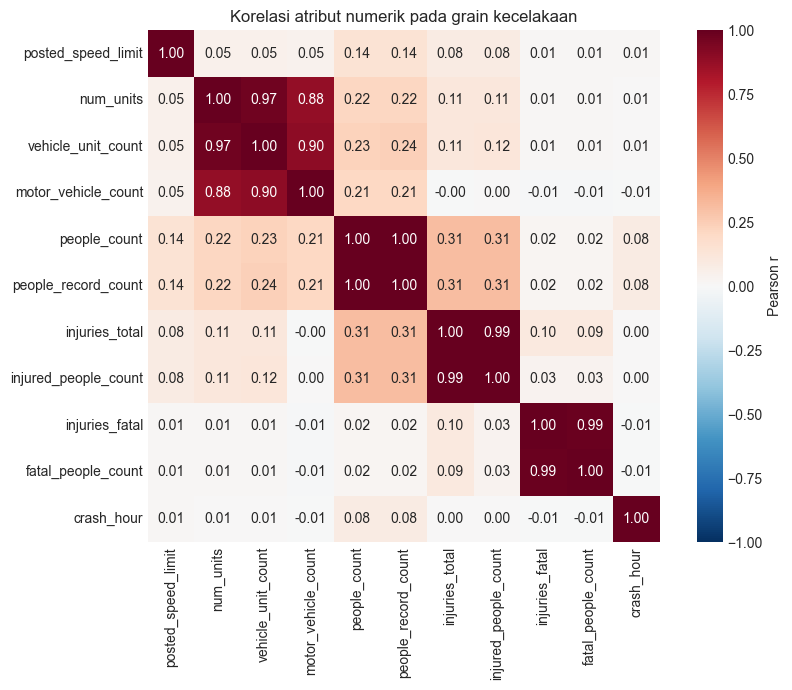

In [12]:
import seaborn as sns

numeric_fields = [
    "posted_speed_limit", "num_units", "vehicle_unit_count", "motor_vehicle_count",
    "people_count", "people_record_count", "injuries_total", "injured_people_count",
    "injuries_fatal", "fatal_people_count", "crash_hour",
]
numeric = pd.read_parquet(processed / "integrated_crashes.parquet", columns=numeric_fields)
numeric = numeric.apply(pd.to_numeric, errors="coerce").astype("float64")
correlation = numeric.corr(method="pearson")
covariance = numeric.cov()
pair_rows = []
for i, left in enumerate(numeric_fields):
    for right in numeric_fields[i+1:]:
        common = numeric[left].notna() & numeric[right].notna()
        pair_rows.append({"atribut_1": left, "atribut_2": right,
                          "korelasi": correlation.loc[left, right],
                          "kovarians": covariance.loc[left, right],
                          "persen_nilai_sama": 100 * numeric.loc[common, left].eq(numeric.loc[common, right]).mean(),
                          "pasangan_teramati": int(common.sum())})
pair_table = pd.DataFrame(pair_rows).sort_values("korelasi", key=lambda v: v.abs(), ascending=False)
display(pair_table.head(10).round(3))
redundant_pairs = pair_table.loc[pair_table["korelasi"].abs().ge(.98)]
print(f"Pasangan dengan |r| ≥ 0,98: {len(redundant_pairs)}")

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(correlation, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            annot=True, fmt=".2f", square=True, cbar_kws={"label": "Pearson r"}, ax=ax)
ax.set_title("Korelasi atribut numerik pada grain kecelakaan")
plt.tight_layout()
plt.show()
del numeric

## 7. Reduksi data dengan pemilihan atribut dan agregasi

PCA dan wavelet tidak digunakan. Tabel ringkas mempertahankan identitas kejadian, waktu, kondisi, jumlah unit/orang, cedera, dan community area. Salinan hitungan yang sangat berkorelasi, alamat rinci, koordinat ganda, serta bulan/jam yang dapat diturunkan dari tanggal tidak disimpan di tabel analisis. Ketiga tabel integrasi lengkap tetap tersedia untuk penelusuran. Dua tabel agregat mengurangi grain menjadi area dan kombinasi hari-jam.

In [13]:
# Satu baris per crash. Simpan atribut penting dan hilangkan salinan konteks yang berulang.
KEEP_COLUMNS = [
    "crash_record_id", "crash_date", "posted_speed_limit", "weather_condition",
    "lighting_condition", "roadway_surface_cond", "first_crash_type", "crash_type",
    "motor_vehicle_count", "people_record_count", "injuries_total", "injuries_fatal",
    "community_area_number", "community_area_name", "community_area_status",
]
source_path = processed / "integrated_crashes.parquet"
reduced_path = processed / "analysis_crashes_reduced.parquet"
analysis_crashes = pd.read_parquet(source_path, columns=KEEP_COLUMNS)
assert analysis_crashes["crash_record_id"].is_unique
analysis_crashes.to_parquet(reduced_path, index=False, compression="zstd")
before_cols = len(pq.ParquetFile(source_path).schema_arrow.names)
after_cols = len(KEEP_COLUMNS)
reduction_summary = pd.DataFrame([{
    "tahap": "Terintegrasi", "baris": len(analysis_crashes), "kolom": before_cols,
    "ukuran_parquet_mb": source_path.stat().st_size / 1024**2,
}, {
    "tahap": "Atribut terpilih", "baris": len(analysis_crashes), "kolom": after_cols,
    "ukuran_parquet_mb": reduced_path.stat().st_size / 1024**2,
}])
display(reduction_summary.round(2))
print(f"Pengurangan atribut: {before_cols-after_cols} ({100*(before_cols-after_cols)/before_cols:.1f}%).")
print("Alasan utama: people_count ≈ people_record_count; injuries_total ≈ injured_people_count;")
print("injuries_fatal ≈ fatal_people_count; crash_hour/crash_month dapat diturunkan dari crash_date;")
print("latitude/longitude/location disederhanakan menjadi community area untuk analisis area.")

,tahap,baris,kolom,ukuran_parquet_mb
0,Terintegrasi,877921,67,130.08
1,Atribut terpilih,877921,15,63.55


Pengurangan atribut: 52 (77.6%).
Alasan utama: people_count ≈ people_record_count; injuries_total ≈ injured_people_count;
injuries_fatal ≈ fatal_people_count; crash_hour/crash_month dapat diturunkan dari crash_date;
latitude/longitude/location disederhanakan menjadi community area untuk analisis area.


## 8. Pola dan hubungan yang ditemukan

Grafik menunjukkan volume kecelakaan menurut tahun, area, hari-jam, dan persentase kecelakaan dengan cedera di setiap kategori cuaca yang memiliki setidaknya 1.000 catatan. Kode hari 1–7 mengikuti sumber. Persentase menurut cuaca memakai hanya baris dengan `injuries_total` diketahui.

,weather_condition,jumlah_kecelakaan,kecelakaan_dengan_cedera,persen_dengan_cedera
2,CLEAR,686208,106727,15.55
7,RAIN,72419,13481,18.62
11,UNKNOWN,54307,2978,5.48
10,SNOW,28825,3670,12.73
3,CLOUDY/OVERCAST,25929,4190,16.16
6,OTHER,2903,547,18.84
5,FREEZING RAIN/DRIZZLE,2406,409,17.0
4,FOG/SMOKE/HAZE,1271,249,19.59
9,SLEET/HAIL,1008,176,17.46


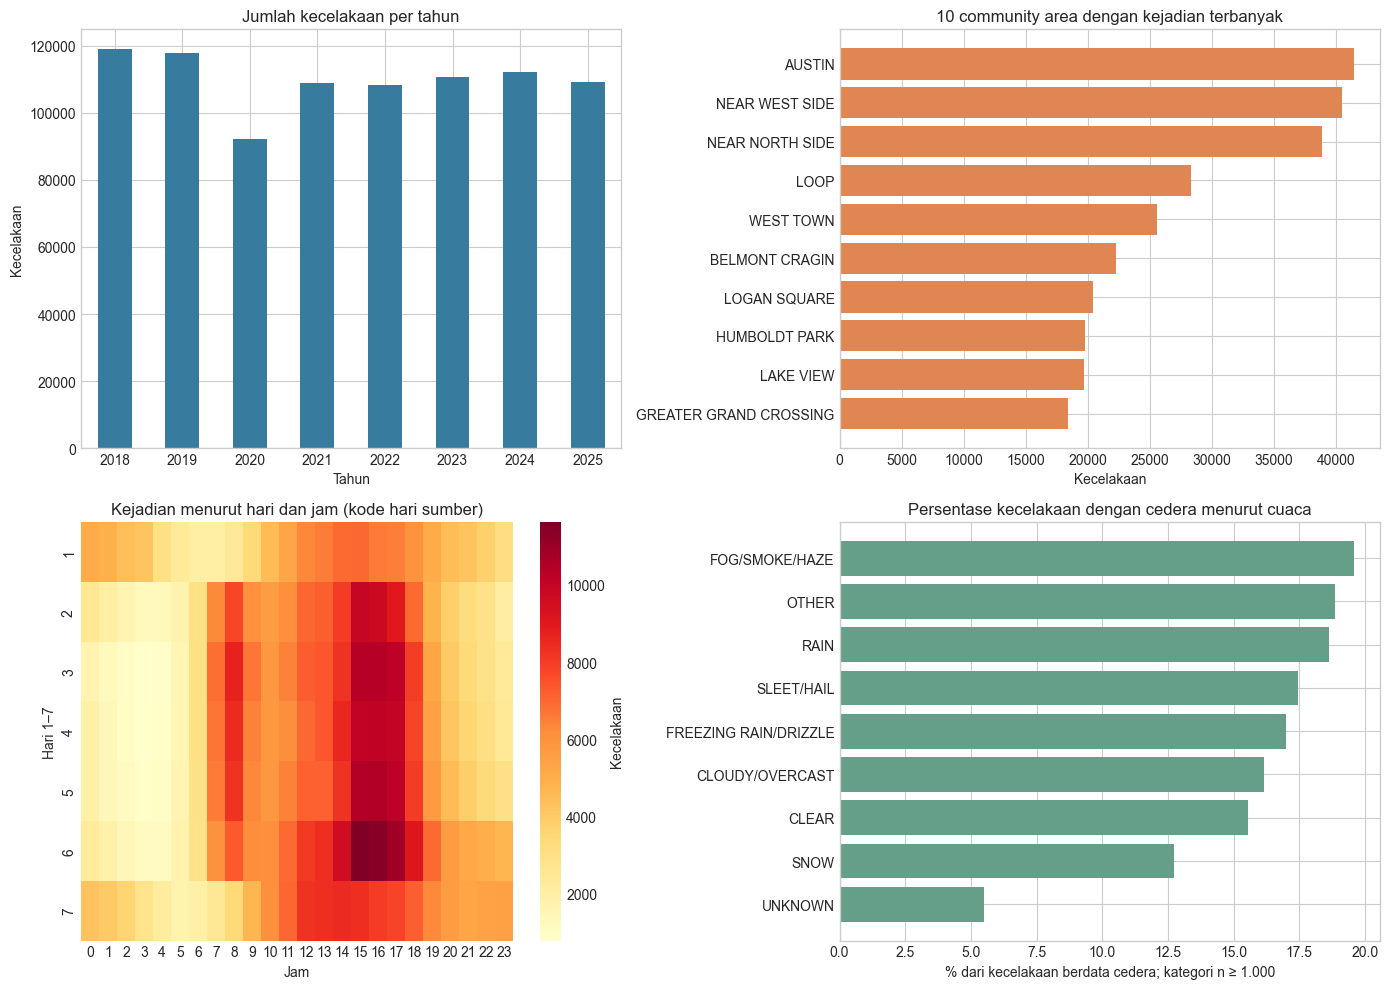

In [14]:
area = pd.read_parquet(processed / "area_impact_summary.parquet")
hour = pd.read_parquet(processed / "hourly_risk_summary.parquet")

analysis_crashes["year"] = analysis_crashes["crash_date"].dt.year
year_counts = analysis_crashes.groupby("year").size()
top_areas = area.nlargest(10, "crash_count").sort_values("crash_count")
hour_grid = hour.pivot(index="crash_day_of_week", columns="crash_hour", values="crash_count")
weather = analysis_crashes.loc[analysis_crashes["injuries_total"].notna()].copy()
weather["has_injury"] = weather["injuries_total"].gt(0)
weather_summary = weather.groupby("weather_condition", dropna=False).agg(
    jumlah_kecelakaan=("has_injury", "size"), kecelakaan_dengan_cedera=("has_injury", "sum")
).reset_index()
weather_summary = weather_summary.loc[weather_summary["jumlah_kecelakaan"].ge(1000)]
weather_summary["persen_dengan_cedera"] = (100 * weather_summary["kecelakaan_dengan_cedera"] /
                                           weather_summary["jumlah_kecelakaan"])
display(weather_summary.sort_values("jumlah_kecelakaan", ascending=False).round(2))

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
year_counts.plot(kind="bar", ax=axes[0, 0], color="#377b9e")
axes[0, 0].set(title="Jumlah kecelakaan per tahun", xlabel="Tahun", ylabel="Kecelakaan")
axes[0, 0].tick_params(axis="x", rotation=0)
axes[0, 1].barh(top_areas["community_area_name"], top_areas["crash_count"], color="#df8652")
axes[0, 1].set(title="10 community area dengan kejadian terbanyak", xlabel="Kecelakaan")
sns.heatmap(hour_grid, cmap="YlOrRd", ax=axes[1, 0], cbar_kws={"label": "Kecelakaan"})
axes[1, 0].set(title="Kejadian menurut hari dan jam (kode hari sumber)", xlabel="Jam", ylabel="Hari 1–7")
w = weather_summary.sort_values("persen_dengan_cedera")
axes[1, 1].barh(w["weather_condition"], w["persen_dengan_cedera"], color="#659e89")
axes[1, 1].set(title="Persentase kecelakaan dengan cedera menurut cuaca",
               xlabel="% dari kecelakaan berdata cedera; kategori n ≥ 1.000")
plt.tight_layout()
plt.show()

## 9. Perbandingan akhir dan kesimpulan

In [15]:
from IPython.display import Markdown

stage_rows = []
for name in ["Crashes", "Vehicle", "People"]:
    clean_name = {"Crashes": "clean_crashes", "Vehicle": "clean_vehicle", "People": "clean_people"}[name]
    clean_file = processed / f"{clean_name}.parquet"
    stage_rows.extend([
        {"dataset": name, "tahap": "Mentah", "baris": int(initial_profile.loc[name, "baris"]),
         "kolom": int(initial_profile.loc[name, "kolom"])},
        {"dataset": name, "tahap": "Bersih", "baris": pq.ParquetFile(clean_file).metadata.num_rows,
         "kolom": len(pq.ParquetFile(clean_file).schema_arrow.names)},
    ])
stage_rows.extend([
    {"dataset": "Crashes", "tahap": "Terintegrasi", "baris": len(analysis_crashes), "kolom": before_cols},
    {"dataset": "Crashes", "tahap": "Terpilih", "baris": len(analysis_crashes), "kolom": after_cols},
    {"dataset": "Community area", "tahap": "Agregat", "baris": len(area), "kolom": len(area.columns)},
    {"dataset": "Hari × jam", "tahap": "Agregat", "baris": len(hour), "kolom": len(hour.columns)},
])
stage_summary = pd.DataFrame(stage_rows)
display(stage_summary)

area_match = int(area["crash_count"].sum())
top_area = area.loc[area["crash_count"].idxmax()]
quietest_year = int(year_counts.idxmin())
peak_slot = hour.loc[hour["crash_count"].idxmax()]
highest_injury_weather = weather_summary.loc[weather_summary["persen_dengan_cedera"].idxmax()]
display(Markdown(f"""
### Ringkasan hasil

- Tiga tabel sumber memuat **{initial_profile['baris'].sum():,} baris** pada grain berbeda; cleaning mempertahankan jumlah baris dan menghapus nilai domain yang tidak valid pada kolom bersih.
- Integrasi mempertahankan **{len(analysis_crashes):,} kecelakaan unik**. Sebanyak **{area_match:,}** dapat dipetakan ke community area; sisanya tetap ada dengan status pemetaan.
- Tabel kecelakaan terpilih berisi **{after_cols} atribut**, dari {before_cols} atribut tabel integrasi (**{100*(before_cols-after_cols)/before_cols:.1f}% lebih sedikit**). Tabel area dan hari-jam adalah agregasi untuk analisis, bukan pengganti data tingkat kejadian.
- Korelasi menunjukkan salinan hitungan orang dan cedera yang hampir sama. Pemilihan atribut mempertahankan satu representasi yang relevan; sumber lengkap dan audit tetap tersimpan.
- Area **{top_area['community_area_name']}** memiliki catatan terbanyak (**{int(top_area['crash_count']):,}**), dan volume tahunan terendah pada **{quietest_year}**. Kombinasi hari-jam tersibuk dalam kode sumber ialah hari **{int(peak_slot['crash_day_of_week'])}**, jam **{int(peak_slot['crash_hour']):02d}.00** (**{int(peak_slot['crash_count']):,}** kejadian).
- Di kategori cuaca dengan sedikitnya 1.000 catatan, **{highest_injury_weather['weather_condition']}** memiliki persentase kecelakaan dengan cedera tertinggi (**{highest_injury_weather['persen_dengan_cedera']:.1f}%**). Ini perbandingan kondisional pada kecelakaan yang tercatat.

**Batas interpretasi:** banyaknya kecelakaan per area/cuaca bukan ukuran risiko lalu lintas karena tidak ada data paparan (misalnya jumlah perjalanan). Koordinat hasil geocoder merupakan estimasi alamat, dan nilai cedera yang tidak dapat dipastikan tetap kosong.
"""))

,dataset,tahap,baris,kolom
0,Crashes,Mentah,877921,49
1,Crashes,Bersih,877921,44
2,Vehicle,Mentah,1792372,71
3,Vehicle,Bersih,1792372,21
4,People,Mentah,1927657,29
5,People,Bersih,1927657,24
6,Crashes,Terintegrasi,877921,67
7,Crashes,Terpilih,877921,15
8,Community area,Agregat,77,13
9,Hari × jam,Agregat,168,9



### Ringkasan hasil

- Tiga tabel sumber memuat **4,597,950 baris** pada grain berbeda; cleaning mempertahankan jumlah baris dan menghapus nilai domain yang tidak valid pada kolom bersih.
- Integrasi mempertahankan **877,921 kecelakaan unik**. Sebanyak **871,586** dapat dipetakan ke community area; sisanya tetap ada dengan status pemetaan.
- Tabel kecelakaan terpilih berisi **15 atribut**, dari 67 atribut tabel integrasi (**77.6% lebih sedikit**). Tabel area dan hari-jam adalah agregasi untuk analisis, bukan pengganti data tingkat kejadian.
- Korelasi menunjukkan salinan hitungan orang dan cedera yang hampir sama. Pemilihan atribut mempertahankan satu representasi yang relevan; sumber lengkap dan audit tetap tersimpan.
- Area **AUSTIN** memiliki catatan terbanyak (**41,495**), dan volume tahunan terendah pada **2020**. Kombinasi hari-jam tersibuk dalam kode sumber ialah hari **6**, jam **15.00** (**11,630** kejadian).
- Di kategori cuaca dengan sedikitnya 1.000 catatan, **FOG/SMOKE/HAZE** memiliki persentase kecelakaan dengan cedera tertinggi (**19.6%**). Ini perbandingan kondisional pada kecelakaan yang tercatat.

**Batas interpretasi:** banyaknya kecelakaan per area/cuaca bukan ukuran risiko lalu lintas karena tidak ada data paparan (misalnya jumlah perjalanan). Koordinat hasil geocoder merupakan estimasi alamat, dan nilai cedera yang tidak dapat dipastikan tetap kosong.
